In [1]:
import pandas as pd
import numpy as np

In [2]:
from qiime2 import Artifact

In [3]:
from skbio.stats import subsample_counts
from skbio.diversity import alpha_diversity

In [4]:
from itertools import combinations, zip_longest

In [5]:
import seaborn as sns
from matplotlib import pyplot as plt
from statannotations.Annotator import Annotator  # puts significance values on box-type plots

In [6]:
%matplotlib inline
sns.set(style='ticks')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'  # render SVG text as text, not curves
plt.rcParams['lines.markersize'] = 15

## taxonomy computations

In [7]:
def taxon2cols(taxon, drop_uncultured=False):
    rank_prefix = (
        "Kingdom",
        "Phylum",
        "Class",
        "Order",
        "Family",
        "Genus",
        "Species",
    )
    ranks = taxon.split("; ")
    if drop_uncultured:
        for n,v in enumerate(ranks):
            if 'metagenome' in v or 'uncultured' in v or v[-1] == '_':
                del ranks[n:]
                break
    return pd.Series(dict(zip_longest(rank_prefix, ranks, fillvalue=ranks[-1])))

In [8]:
tax_file = '/mnt/zarrinpar/Pynchon/Databases/wol2/taxonomy/lineages.txt'
tax = pd.read_csv(tax_file, sep='\t', names=['genome', 'lineage'], index_col=0)
tax.head()

,lineage
genome,
G000005825,d__Bacteria; p__Firmicutes; c__Bacilli; o__Bac...
G000006175,d__Archaea; p__Methanobacteriota_A; c__Methano...
G000006605,d__Bacteria; p__Actinobacteriota; c__Actinomyc...
G000006725,d__Bacteria; p__Proteobacteria; c__Gammaproteo...
G000006745,d__Bacteria; p__Proteobacteria; c__Gammaproteo...


In [9]:
# get species/family names
tax_tbl = tax.lineage.apply(lambda x: taxon2cols(x, drop_uncultured=True))
tax_tbl['species_name'] = tax_tbl.index.to_frame()['genome'].str[-4:] + ":" + tax_tbl.Species
tax_tbl['family_name'] = tax_tbl.index.to_frame()['genome'].str[-4:] + ":" + tax_tbl.Family
tax_tbl.head()


,Kingdom,Phylum,Class,Order,Family,Genus,Species,species_name,family_name
genome,,,,,,,,,
G000005825,d__Bacteria,p__Firmicutes,c__Bacilli,o__Bacillales_H,f__Bacillaceae_D,g__Bacillus_S,s__Bacillus_S pseudofirmus,5825:s__Bacillus_S pseudofirmus,5825:f__Bacillaceae_D
G000006175,d__Archaea,p__Methanobacteriota_A,c__Methanococci,o__Methanococcales,f__Methanococcaceae,g__Methanococcus,s__Methanococcus voltae_A,6175:s__Methanococcus voltae_A,6175:f__Methanococcaceae
G000006605,d__Bacteria,p__Actinobacteriota,c__Actinomycetia,o__Mycobacteriales,f__Mycobacteriaceae,g__Corynebacterium,s__Corynebacterium jeikeium,6605:s__Corynebacterium jeikeium,6605:f__Mycobacteriaceae
G000006725,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Xanthomonadales,f__Xanthomonadaceae,g__Xylella,s__Xylella fastidiosa,6725:s__Xylella fastidiosa,6725:f__Xanthomonadaceae
G000006745,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Enterobacterales,f__Vibrionaceae,g__Vibrio,s__Vibrio cholerae,6745:s__Vibrio cholerae,6745:f__Vibrionaceae


# load metadata

In [10]:
md = pd.read_csv('stool.metagenomic.metadata.with_amyloid.tsv', sep='\t', index_col=0)
sorted(list(md.columns))

['TRF_start_age_mo',
 'TRF_start_date',
 'age_of_collection_days',
 'age_of_collection_months',
 'box',
 'brain_insoluble_ab40',
 'brain_insoluble_ab42',
 'brain_lysate_ab40',
 'brain_lysate_ab42',
 'brain_soluble_ab40',
 'brain_soluble_ab42',
 'cage_id',
 'collection_timepoint',
 'collection_timestamp',
 'dab_area_cortex',
 'dab_area_hippocampus',
 'dab_count_cortex',
 'dab_count_hippocampus',
 'date_of_collection',
 'description',
 'dna_extracted',
 'dob',
 'elevation',
 'empo_1',
 'empo_2',
 'empo_3',
 'env_biome',
 'env_feature',
 'env_material',
 'env_package',
 'feeding_condition',
 'genotype_diet',
 'geo_loc_name',
 'host_age',
 'host_age_units',
 'host_body_habitat',
 'host_body_product',
 'host_body_site',
 'host_common_name',
 'host_scientific_name',
 'host_subject_id',
 'host_taxid',
 'host_weight',
 'host_weight_units',
 'iacuc_institute',
 'iacuc_protocol_id',
 'katharoseq_cell_count',
 'katharoseq_community_type',
 'katharoseq_control_type',
 'katharoseq_plate_number',
 '

In [11]:
md.drop([r for r in md.index if 'BLANK' in r], inplace=True)

In [12]:
md['genotype_diet'] = md.mouse_genotype + "." + md.feeding_condition
md.genotype_diet.value_counts()

Tg.ALF     53
Tg.TRF     50
Ntg.ALF    42
Name: genotype_diet, dtype: int64

In [13]:
genotype_diet_order = ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF']
genotype_diet_groups = [
    ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF'],
    ['Ntg.ALF', 'Tg.ALF'],
    ['Tg.ALF', 'Tg.TRF'],
]
genotype_diet_palette = {
    'Tg.ALF': 'purple',
    'Ntg.ALF': 'orange',
    'Tg.TRF': 'green',
}

In [14]:
sex_order = ('male', 'female')
sex_markers = {'male': 'o', 'female': 'D'}

In [15]:
md['zt_time'] = md.zt_collection_time.str.replace('ZT','', regex=False).astype(int)
md['zt_collection_time'] = 'ZT' + md.zt_time.astype(str).str.zfill(2)
md.zt_collection_time.unique()

array(['ZT08', 'ZT20', 'ZT12', 'ZT16', 'ZT00', 'ZT04'], dtype=object)

In [16]:
md.head()

,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,serum_ab40_ab42_ratio,serum_ab42_ab40_ratio,brain_lysate_ab40,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time
sample_name,,,,,,,,,,,,,,,,,,,,,
14708.332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,18.073368,0.055330,406.741573,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8
14708.314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,3.468113,0.288341,460.338983,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20
14708.320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8
14708.319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12
14708.322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16


# Genome counts

In [17]:
genome_counts = Artifact.load('metagenomic/159171_rs210_per_genome.feature-table.qza').view(pd.DataFrame)

In [18]:
genome_counts.info()

<class 'pandas.core.frame.DataFrame'>
Index: 161 entries, 14708.329.T16.S to 14708.323.T20.S
Columns: 12853 entries, G000001985 to G920984865
dtypes: float64(12853)
memory usage: 15.8+ MB


In [19]:
# no blanks
genome_counts.drop([c for c in genome_counts.index if 'BLANK' in c], inplace=True)

In [20]:
genome_counts.T.sum().describe()

count    1.450000e+02
mean     2.543018e+06
std      1.650659e+06
min      6.483440e+05
25%      1.327753e+06
50%      2.299963e+06
75%      2.990590e+06
max      9.682784e+06
dtype: float64

In [21]:
# rarefaction
genome_int = genome_counts.apply(
    result_type='expand',
    func=lambda x: x.round().astype(int)
)

limit = genome_int.sum(axis=1).min()
print(limit)

genome_all_rarefy = genome_int.apply(
    axis='columns', 
    result_type='expand',
    func=lambda x: subsample_counts(x, limit, replace=True)
)
genome_all_rarefy.columns = genome_int.columns
genome_all_rarefy.T.sum().describe()

648344


count       145.0
mean     648344.0
std           0.0
min      648344.0
25%      648344.0
50%      648344.0
75%      648344.0
max      648344.0
dtype: float64

In [22]:
genome_all_rarefy.drop(
    genome_all_rarefy.T[genome_all_rarefy.sum() ==0].index, 
    axis=1,
    inplace=True,
)

In [23]:
genome_all_rarefy

,G000002415,G000002435,G000002445,G000002495,G000002655,G000002765,G000002825,G000002845,G000002855,G000002875,...,G905142465,G905367715,G905397375,G907166805,G910574115,G910575425,G910576415,G918814575,G918814755,G920984865
14708.329.T16.S,0,1,0,0,0,0,0,0,0,0,...,0,0,2,0,0,20863,0,0,0,0
14708.332.T20.S,0,0,0,0,0,0,1,0,1,0,...,0,0,0,0,0,10546,0,0,0,0
14708.303.T12.S,1,1,1,0,0,0,0,0,1,0,...,0,0,0,0,26,19923,0,0,0,0
14708.330.T16.S,0,3,0,0,0,0,0,0,0,0,...,0,0,8,0,3,10125,0,0,0,0
14708.304.T0.S,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,7,19395,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14708.323.T0.S,4,0,0,0,0,0,3,0,0,0,...,0,0,5,0,0,13896,0,0,0,0
14708.322.T16.S,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,35172,0,0,0,0
14708.323.T16.S,0,0,1,0,0,0,0,0,0,0,...,0,0,2,0,2,11025,0,0,0,0
14708.323.T12.S,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,6,6017,0,0,1,0


In [24]:
md.loc[genome_all_rarefy.index].genotype_diet.value_counts()

Tg.ALF     53
Tg.TRF     50
Ntg.ALF    42
Name: genotype_diet, dtype: int64

## Calc alpha diversity

In [25]:
family_rarefy = genome_all_rarefy.T.join(tax_tbl.Family, how='left').groupby('Family').agg(np.sum)
family_chao = alpha_diversity('chao1', family_rarefy.T, ids=family_rarefy.columns)
family_chao.name = 'Family_Chao1'
species_rarefy = genome_all_rarefy.T.join(tax_tbl.Species, how='left').groupby('Species').agg(np.sum)
species_chao = alpha_diversity('chao1', species_rarefy.T, ids=species_rarefy.columns)
species_chao.name ='Species_Chao1'
genome_chao = alpha_diversity('chao1', genome_all_rarefy, ids=genome_all_rarefy.index)
genome_chao.name='Genome_Chao1'

In [26]:
chao_md = md.join(family_chao).join(species_chao).join(genome_chao)

In [27]:
chao_md

,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time,Family_Chao1,Species_Chao1,Genome_Chao1
sample_name,,,,,,,,,,,,,,,,,,,,,
14708.332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8,94.545455,427.250000,1428.774510
14708.314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20,152.142857,523.620690,2649.728395
14708.320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8,99.714286,400.837838,1307.333333
14708.319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12,89.230769,405.609756,1262.275862
14708.322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16,99.230769,391.756757,1410.059701
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14708.330.T0.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,0,102.000000,414.634146,1644.520000
14708.330.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,12,91.714286,505.294118,1778.480769
14708.330.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,16,125.375000,477.944444,1618.827586


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.869e-01 U_stat=1.040e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.748e-01 U_stat=1.159e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.101e-02 U_stat=8.105e+02


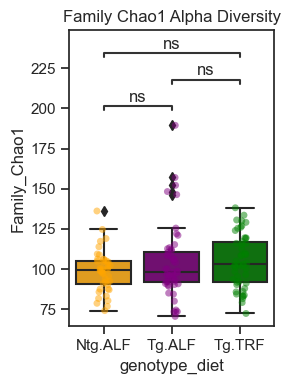

In [28]:
plt.subplots(figsize=(3,4))
comparison_pairs = (
    ('Ntg.ALF', 'Tg.ALF',),
    ('Tg.ALF', 'Tg.TRF',),
    ('Ntg.ALF', 'Tg.TRF'),
)
plot_args = {
    'data': chao_md,
    'y': 'Family_Chao1',
    'x': 'genotype_diet',
    'order': genotype_diet_order,
    'palette': genotype_diet_palette,
}
ax = sns.stripplot(dodge=True, alpha=0.5, color='0.3', **plot_args)
sns.boxplot(ax=ax, **plot_args,)
annotator = Annotator(ax, comparison_pairs, **plot_args)  # add statistics
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()
plt.title('Family Chao1 Alpha Diversity')
plt.tight_layout()
plt.savefig('images/metagenomic.alpha.chao1.family.svg')
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.611e-01 U_stat=1.172e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.775e-05 U_stat=7.150e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.997e-04 U_stat=5.750e+02


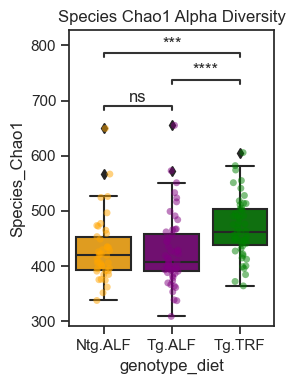

In [29]:
plt.subplots(figsize=(3,4))
comparison_pairs = (
    ('Ntg.ALF', 'Tg.ALF',),
    ('Tg.ALF', 'Tg.TRF',),
    ('Ntg.ALF', 'Tg.TRF'),
)
plot_args = {
    'data': chao_md,
    'y': 'Species_Chao1',
    'x': 'genotype_diet',
    'order': genotype_diet_order,
    'palette': genotype_diet_palette,
}
ax = sns.stripplot(dodge=True, alpha=0.5, color='0.3', **plot_args)
sns.boxplot(ax=ax, **plot_args,)
annotator = Annotator(ax, comparison_pairs, **plot_args)  # add statistics
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()
plt.title('Species Chao1 Alpha Diversity')
plt.tight_layout()
plt.savefig('images/metagenomic.alpha.chao1.species.svg')
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.162e-01 U_stat=1.222e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.569e-05 U_stat=6.700e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.887e-05 U_stat=5.370e+02


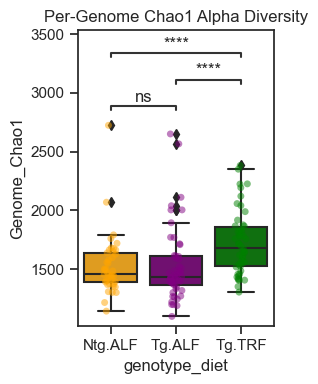

In [30]:
plt.subplots(figsize=(3,4))
comparison_pairs = (
    ('Ntg.ALF', 'Tg.ALF',),
    ('Tg.ALF', 'Tg.TRF',),
    ('Ntg.ALF', 'Tg.TRF'),
)
plot_args = {
    'data': chao_md,
    'y': 'Genome_Chao1',
    'x': 'genotype_diet',
    'order': genotype_diet_order,
    'palette': genotype_diet_palette,
}
ax = sns.stripplot(dodge=True, alpha=0.5, color='0.3', **plot_args)
sns.boxplot(ax=ax, **plot_args,)
annotator = Annotator(ax, comparison_pairs, **plot_args)  # add statistics
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()
plt.title('Per-Genome Chao1 Alpha Diversity')
plt.tight_layout()
plt.savefig('images/metagenomic.alpha.chao1.genome.svg')
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

8_Ntg.ALF vs. 8_Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.789e-01 U_stat=2.500e+01
8_Tg.ALF vs. 8_Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.351e-01 U_stat=1.400e+01
20_Ntg.ALF vs. 20_Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.371e-01 U_stat=3.400e+01
20_Tg.ALF vs. 20_Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.407e-02 U_stat=1.600e+01
12_Ntg.ALF vs. 12_Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.079e-01 U_stat=4.000e+01
12_Tg.ALF vs. 12_Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.044e-02 U_stat=1.100e+01
16_Ntg.ALF vs. 16_Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.073e-02 U_stat=4.800e+01
16_Tg.ALF vs. 16_Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.407e-02 U_stat=1.600e+01
4_Tg.ALF vs. 4_Tg.TRF: Mann-Whitney-Wilc

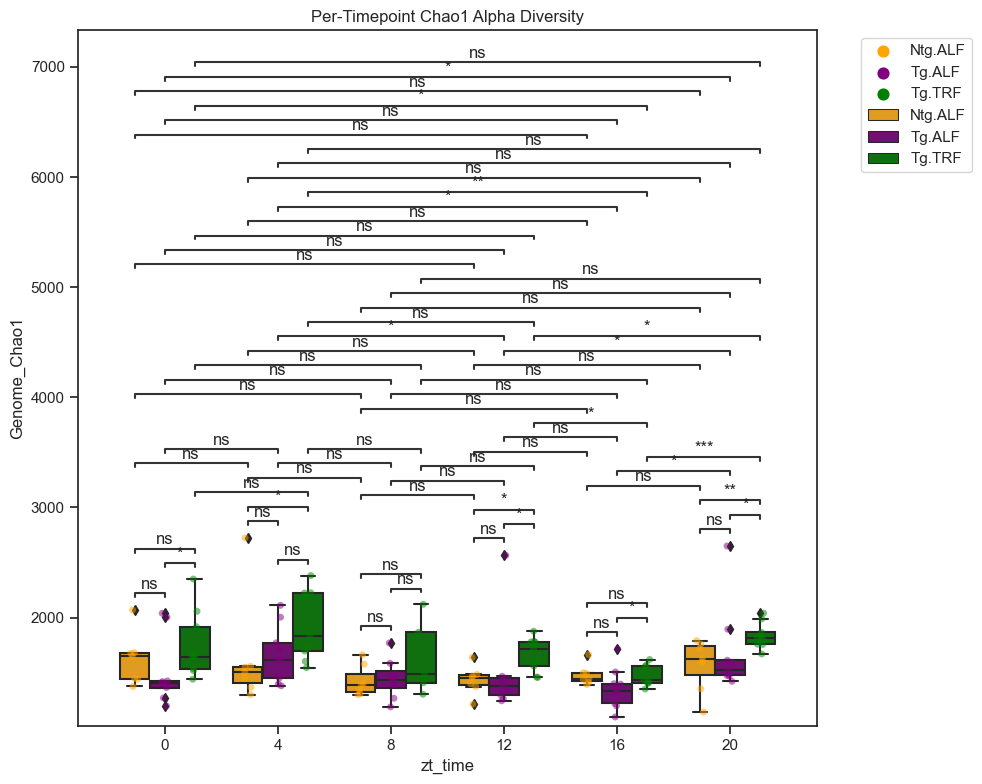

In [31]:
# Per-timepoint alpha diversity

plt.subplots(figsize=(10,8))
comparison_pairs = []
for zt in chao_md.zt_time.unique():
    comparison_pairs.extend(
        (
            ((zt, 'Ntg.ALF'), (zt,'Tg.ALF'), ),
            ((zt, 'Tg.ALF'), (zt, 'Tg.TRF'), ),
            ((zt, 'Ntg.ALF'), (zt, 'Tg.TRF'), ),
        )
    )
for zt1,zt2 in combinations(chao_md.zt_time.unique(), 2):
    comparison_pairs.extend(
        (
            ((zt1, 'Ntg.ALF'), (zt2, 'Ntg.ALF'), ),
            ((zt1, 'Tg.ALF'), (zt2, 'Tg.ALF'), ),
            ((zt1, 'Tg.TRF'), (zt2, 'Tg.TRF'), ),
        )
    )
plot_args = {
    'data': chao_md,
    'y': 'Genome_Chao1',
    'x': 'zt_time',
    'hue': 'genotype_diet',
    'hue_order': genotype_diet_order,
    'palette': genotype_diet_palette,
}
ax = sns.stripplot(dodge=True, alpha=0.5, color='0.3', **plot_args)
sns.boxplot(ax=ax, **plot_args,)
annotator = Annotator(ax, comparison_pairs, show_non_significant=False, **plot_args)  # add statistics
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()
plt.legend(bbox_to_anchor=(1.05, 1))
plt.title('Per-Timepoint Chao1 Alpha Diversity')
plt.tight_layout()
plt.savefig('images/metagenomic.alpha.chao1.per_timepoint.genome.svg')
plt.show()

## Faiths

In [42]:
faiths = Artifact.load('metagenomic/core_metrics_phlyogenetic/faith_pd_vector.qza').view(pd.Series)
md_i = md.copy()
md_i.index = md.index.to_frame().sample_name.str.replace(r'^\d+\.','', regex=True)
faiths = md_i.join(faiths)
faiths

,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,serum_ab42_ab40_ratio,brain_lysate_ab40,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time,faith_pd
sample_name,,,,,,,,,,,,,,,,,,,,,
332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,0.055330,406.741573,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8,175.713306
314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,0.288341,460.338983,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20,156.689684
320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8,178.721496
319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12,154.162261
322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16,151.462849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330.T0.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,0,215.050355
330.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,12,197.176607
330.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,16,209.790958


,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,serum_ab40_ab42_ratio,serum_ab42_ab40_ratio,brain_lysate_ab40,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time
sample_name,,,,,,,,,,,,,,,,,,,,,
14708.332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,18.073368,0.055330,406.741573,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8
14708.314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,3.468113,0.288341,460.338983,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20
14708.320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8
14708.319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12
14708.322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14708.330.T0.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.285637,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,0
14708.330.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.285637,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,12
14708.330.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,17.285637,0.057851,262.921348,17.415730,67589.712919,20266.746411,262.921348,17.415730,Tg.TRF,16
